In [2]:
# Import required libraries
import sys
print(sys.executable)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from pathlib import Path
from skimage import io
from skimage.io import imread_collection
import datetime
import re
import builtins
import os
import imageio.v2 as imageio
from IPython.display import Image, display
from collections import defaultdict

/mnt/large_storage/shared_storage/data/Yuhang/dphil_mothermachine/.venv/bin/python


In [3]:
# Functions to parse metadata from filenames

def get_led(filename: str) -> str:
    return filename.split("/")[-1].split("_")[0]

def get_fov(filename: str) -> int:
    return int(filename.split("/")[-1].split("_")[1][1:])

def get_str(filename: str) -> str:
    parts = filename.split("/")[-1].split("_")
    return " ".join([parts[0], parts[1], parts[-1].split(".")[0]])

def sort_by_time(file_list):
    timestamp_pattern = re.compile(r"(\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2}-\d{6})")
    timestamps = [timestamp_pattern.search(f.split("/")[-1]).group(1) for f in file_list]
    times = [datetime.datetime.strptime(ts, "%Y-%m-%d_%H-%M-%S-%f") for ts in timestamps]
    return [f for _, f in sorted(zip(times, file_list))]

In [ ]:
# INPUT experiment name
data_folder = "2026-09-22_wmmet+_test2_full"

# Brightness specification
FIXED_RANGES = {
    "LED450NM": (332, 5640),
    "LED515NM": (700, 14000),
    "LEDOVERHEADTIGER": (100, 5000),
}
AUTO_BRIGHTNESS = True  # Set to True to enable auto brightness adjustment

# INPUT LED selection (multiple may be selected, e.g., ["LED515NM", "LEDOVERHEADTIGER"])

#sel_led = ["LED515NM", "LEDOVERHEADTIGER"]
sel_led = ["LED450NM"]

# Path specification
repo_path = Path.cwd()
data_path = repo_path.parent / f"{data_folder}"
output_path = data_path / "Processed" 
output_path.mkdir(parents=True, exist_ok=True)

if not data_path.exists():
    raise FileNotFoundError(f"data_path does not exist: {data_path}")

print(f"  data_path        = {data_path}")
print(f"  experiment_name  = {data_folder}")
print(f"  output_path      = {output_path}")

  data_path        = /mnt/large_storage/shared_storage/data/Yuhang/2026-09-22_wmmet+_test2_full
  experiment_name  = 2026-09-22_wmmet+_test2_full
  output_path      = /mnt/large_storage/shared_storage/data/Yuhang/2026-09-22_wmmet+_test2_full/Processed


In [6]:

# File discovery

image_patterns = ["*.tif", "*.tiff", "*.ome.tif", "*.ome.tiff"]
filenames = []
for pattern in image_patterns:
    filenames.extend(data_path.rglob(pattern)) # recursively search for image files

filenames = sorted({str(f) for f in filenames})

print(f"Loaded {len(filenames)} images \n")

# Diagnostic: check file counts and timestamp uniqueness per LED/FOV

files_by_led = defaultdict(list)
files_by_led_by_fov = defaultdict(lambda: defaultdict(list))

for f in filenames:
    led = get_led(f)
    fov = get_fov(f)
    files_by_led[led].append(f)
    files_by_led_by_fov[led][fov].append(f)

print(f"Files per LED:")

for led in sorted(files_by_led):
    print(f"{led}: {len(files_by_led[led])} files")
    # for fov in sorted(files_by_led_by_fov[led]):
    #     print(f"  FOV {fov}: {len(files_by_led_by_fov[led][fov])} files")

Loaded 7880 images 

Files per LED:
LED450NM: 3900 files
LED515NM: 20 files
LED565NM: 20 files
LED645NM: 20 files
LEDOVERHEAD: 20 files
LEDOVERHEADTIGER: 3900 files


In [7]:
# # ================================================================
# # Identify corrupted TIFFs (read test)
# # ================================================================

# from tqdm import tqdm  # progress bar
# import warnings

# # Configure read test: try full read, fall back to header-only if needed
# def _read_test(path_str):
#     try:
#         # Read to force decode; if image is large, this may be slow but reliable
#         _ = io.imread(path_str)
#         return True, None
#     except Exception as exc:
#         return False, exc

# bad_files = []
# good_files = []

# # Optional: silence skimage warnings that do not indicate corruption
# with warnings.catch_warnings():
#     warnings.simplefilter("ignore")
#     for f in tqdm(filenames, desc="Validating TIFFs"):
#         ok, exc = _read_test(f)
#         if ok:
#             good_files.append(f)
#         else:
#             bad_files.append((f, exc))

# print(f"Total files: {len(filenames)}")
# print(f"Good files : {len(good_files)}")
# print(f"Bad files  : {len(bad_files)}")

# if bad_files:
#     print("\nBad files (first 20):")
#     for f, exc in bad_files[:20]:
#         print(f"- {Path(f).name}: {type(exc).__name__} - {exc}")

# # Use this filtered list for downstream processing if desired
# filenames = good_files

In [8]:


# Select LED
for led in sel_led:
    if not (led.startswith('LED') and (led.endswith('NM') or led.endswith('OVERHEAD') or led.endswith('OVERHEADTIGER'))):
        raise ValueError(f"Invalid LED format: {led}. Expected format: LED<wavelength>NM or LEDOVERHEAD")

print(f"Selected LEDs = {sel_led}")

# Group filenames by position for the selected LEDs
fovs_by_led = {}
filenames_by_fov_by_led = {}

for led in sel_led:
    fovs_by_led[led] = np.unique([get_fov(f) for f in filenames if get_led(f) == led])
    filenames_by_fov_by_led[led] = {
        fov: sort_by_time([f for f in filenames if get_led(f) == led and get_fov(f) == fov])
        for fov in fovs_by_led[led]
    }

# Load images per position per LED
imgs_by_led = {}

for led in sel_led:
    imgs_by_led[led] = []
    for fov in fovs_by_led[led]:
        if filenames_by_fov_by_led[led][fov]:
            imgs_by_led[led].append(imread_collection(filenames_by_fov_by_led[led][fov]))


# Diagnostic: check file counts and timestamp uniqueness per LED/FOV

for led in sel_led:
    print(f"\n{led} - {len(fovs_by_led[led])} total files found accross {len(fovs_by_led[led])} FOVs")
    for fov in fovs_by_led[led]:
        files = filenames_by_fov_by_led[led][fov]
        if len(files) <= len(fovs_by_led[led]):
             raise ValueError(
                f"User selected {led}, but this LED has only one file per FOV. "
                f"The LED was likely only used for initialisation and did not image over time")
        print(f"  FOV {fov}: files={len(files)}")

Selected LEDs = ['LED450NM']

LED450NM - 20 total files found accross 20 FOVs
  FOV 0: files=195
  FOV 1: files=195
  FOV 2: files=195
  FOV 3: files=195
  FOV 4: files=195
  FOV 5: files=195
  FOV 6: files=195
  FOV 7: files=195
  FOV 8: files=195
  FOV 9: files=195
  FOV 10: files=195
  FOV 11: files=195
  FOV 12: files=195
  FOV 13: files=195
  FOV 14: files=195
  FOV 15: files=195
  FOV 16: files=195
  FOV 17: files=195
  FOV 18: files=195
  FOV 19: files=195


Plotting FOV no 0


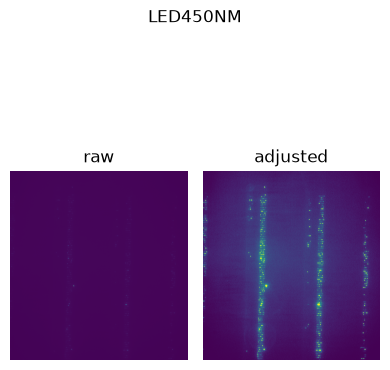

In [9]:
# INPUT image adjustment parameters

fov_to_display = 0
v_min_perc = [20]
v_max_perc = [99.8]

y_min, y_max, x_min, x_max = 0, 30000, 0, 3000
#y_min, y_max, x_min, x_max = 0, 3200, 0, 600

if len(v_min_perc) != len(sel_led) or len(v_max_perc) != len(sel_led):
    raise ValueError(f"Expected {len(sel_led)} values in v_min_perc and v_max_perc - one per selected LED")

print(f"Plotting FOV no {fov_to_display}")

# Display cropped images with raw and adjusted contrast per LED

for i, led in enumerate(sel_led):
    if fov_to_display not in filenames_by_fov_by_led[led]:
        fig, axes = plt.subplots(1, 2, figsize=(6, 3))
        axes[0].set_axis_off()
        axes[1].set_axis_off()
        fig.suptitle(led)
        axes[0].set_title("FOV not found")
        plt.tight_layout()
        plt.show()
        continue

    first_file = filenames_by_fov_by_led[led][fov_to_display][0]
    img = io.imread(first_file)[y_min:y_max, x_min:x_max]
    if AUTO_BRIGHTNESS:
        v_min = np.percentile(img, v_min_perc[i])
        v_max = np.percentile(img, v_max_perc[i])
    else:
        v_min, v_max = FIXED_RANGES[led]

    fig, axes = plt.subplots(1, 2, figsize=(4, 5))
    fig.suptitle(led)
    axes[0].imshow(img, cmap="viridis")
    axes[0].set_title("raw")

    axes[1].imshow(img, cmap="viridis", vmin=v_min, vmax=v_max)
    axes[1].set_title("adjusted")

    axes[0].axis("off")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

In [11]:
# ================================================================
# FIND FIXED DISPLAY RANGE FROM THE DATA
# ================================================================
fov_exclude = [19]

for led in sel_led:

    pixel_values = []

    for fov_index, image_collection in enumerate(imgs_by_led[led]):
        if fov_index in fov_exclude:
            print(f"Skipping FOV {fov_index} for LED {led} as it is in the exclusion list.")
            continue

        for img in image_collection[::10]:
            # Apply the same crop used for the GIF
            cropped = img[y_min:y_max, x_min:x_max]

            # Flatten and store
            pixel_values.append(cropped.ravel())

    # Combine sampled pixels
    pixel_values = np.concatenate(pixel_values)

    # Calculate the fixed limits
    fixed_vmin = np.percentile(pixel_values, 20)
    fixed_vmax = np.percentile(pixel_values, 99.8)

    print(f"\n{led}")
    print(f"20th percentile  = {fixed_vmin:.1f}")
    print(f"99.8th percentile = {fixed_vmax:.1f}")

Skipping FOV 19 for LED LED450NM as it is in the exclusion list.

LED450NM
20th percentile  = 332.0
99.8th percentile = 5640.0


Calculating brightness: LED450NM, FOV 0
Calculating brightness: LED450NM, FOV 1
Calculating brightness: LED450NM, FOV 2
Calculating brightness: LED450NM, FOV 3
Calculating brightness: LED450NM, FOV 4
Calculating brightness: LED450NM, FOV 5
Calculating brightness: LED450NM, FOV 6
Calculating brightness: LED450NM, FOV 7
Calculating brightness: LED450NM, FOV 8
Calculating brightness: LED450NM, FOV 9
Calculating brightness: LED450NM, FOV 10
Calculating brightness: LED450NM, FOV 11
Calculating brightness: LED450NM, FOV 12
Calculating brightness: LED450NM, FOV 13
Calculating brightness: LED450NM, FOV 14
Calculating brightness: LED450NM, FOV 15
Calculating brightness: LED450NM, FOV 16
Calculating brightness: LED450NM, FOV 17
Calculating brightness: LED450NM, FOV 18
Calculating brightness: LED450NM, FOV 19

Brightness analysis complete.
Total frames analysed: 3900
Brightness table saved to: /mnt/large_storage/shared_storage/data/Yuhang/2026-09-22_wmmet+_test2_full/Processed/frame_brightness.cs

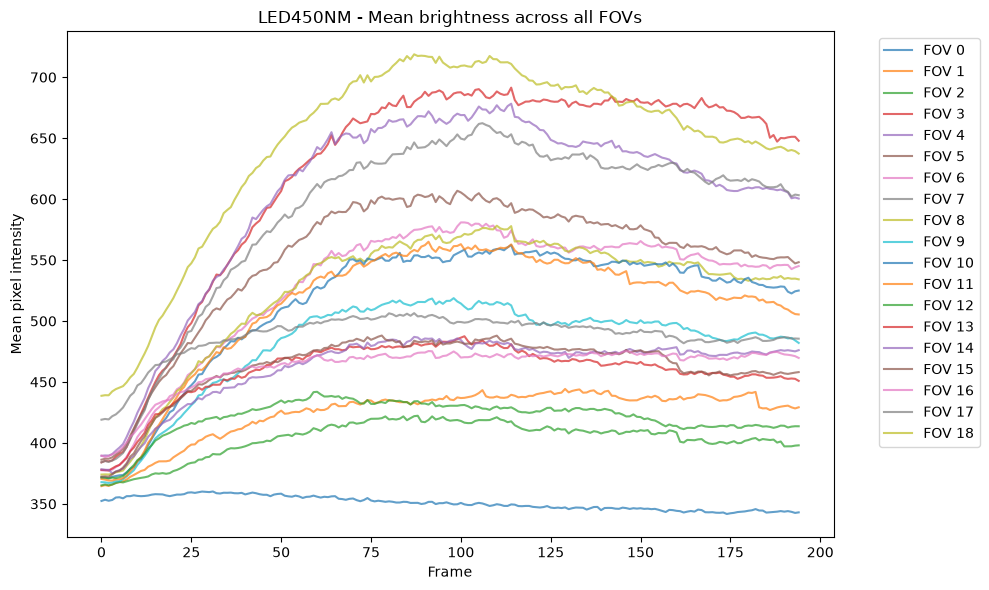

In [ ]:
# ================================================================
# FRAME-BY-FRAME BRIGHTNESS ANALYSIS
# TOP X% BRIGHTEST PIXELS
#
# For every frame in every FOV:
#   1. Read ALL pixels within the selected ROI
#   2. Select the brightest X% of pixels
#   3. Calculate their mean and standard deviation
#   4. Save the results to CSV
# ================================================================

import numpy as np
import pandas as pd

# ------------------------------------------------
# SETTINGS
# ------------------------------------------------

# Percentage of brightest pixels to analyse
TOP_PERCENT = 5

# Output CSV
brightness_csv = output_path / f"frame_brightness_top_{TOP_PERCENT}_pixels.csv"

brightness_results = []

# ------------------------------------------------
# ANALYSE EVERY LED AND FOV
# ------------------------------------------------

for led in sel_led:

    for fov_index, image_collection in enumerate(imgs_by_led[led]):

        # Actual FOV number
        fov = fovs_by_led[led][fov_index]

        print(f"Analysing {led}, FOV {fov}")

        # ------------------------------------------------
        # ANALYSE EVERY FRAME
        # ------------------------------------------------

        for frame_index, img in enumerate(image_collection):

            # Apply same ROI as GIFs / PNGs
            cropped = img[
                y_min:y_max,
                x_min:x_max
            ]

            # Flatten ALL pixels into a 1D array
            pixels = cropped.ravel()

            # Number of pixels to select
            n_top = max(
                1,
                int(np.ceil(len(pixels) * TOP_PERCENT / 100))
            )

            # Select the brightest X% of pixels
            # More memory-efficient than sorting all pixels
            top_pixels = np.partition(
                pixels,
                len(pixels) - n_top
            )[-n_top:]

            # Calculate statistics
            mean_brightness = np.mean(top_pixels)
            std_brightness = np.std(top_pixels)

            # Store results
            brightness_results.append({
                "LED": led,
                "FOV": fov,
                "Frame": frame_index,
                "Top_Percent": TOP_PERCENT,
                "N_Pixels": n_top,
                "Mean_Brightness": mean_brightness,
                "Std_Brightness": std_brightness,
            })

# ------------------------------------------------
# CREATE DATAFRAME
# ------------------------------------------------

brightness_df = pd.DataFrame(brightness_results)

# Save to CSV
brightness_df.to_csv(
    brightness_csv,
    index=False
)

print("\nBrightness analysis complete.")
print(f"Total frames analysed: {len(brightness_df)}")
print(f"Top pixel percentage: {TOP_PERCENT}%")
print(f"Saved to: {brightness_csv}")

display(brightness_df)


# ================================================================
# PLOT TOP X% BRIGHTNESS ACROSS ALL FOVs
# ================================================================
fov_exclude = [19]  # List of FOVs to exclude from the plot

for led in sel_led:

    led_data = brightness_df[
        brightness_df["LED"] == led
    ]

    plt.figure(figsize=(11, 6))

    for fov in sorted(led_data["FOV"].unique()):
        if fov in fov_exclude:
            print(f"Skipping FOV {fov} for LED {led} as it is in the exclusion list.")
            continue

        fov_data = led_data[
            led_data["FOV"] == fov
        ].sort_values("Frame")

        plt.plot(
            fov_data["Frame"],
            fov_data["Mean_Brightness"],
            label=f"FOV {fov}",
            alpha=0.8
        )

    plt.xlabel("Frame")
    plt.ylabel("Mean raw pixel intensity (top 5%)")
    plt.title(
        f"{led} - Top {TOP_PERCENT}% brightest pixels"
    )

    plt.legend(
        bbox_to_anchor=(1.05, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# ================================================================
# SAVE FULL-RESOLUTION VIRIDIS PNG FRAMES
# Uses fixed or autobrightness and creates a separate folder
# for each FOV.
# ================================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.colors import Normalize
from skimage import io

# ------------------------------------------------
# Settings
# ------------------------------------------------
AUTO_BRIGHTNESS = False  # Set to True to enable auto brightness adjustment
# Output folder
if AUTO_BRIGHTNESS:
    png_output_path = output_path / "PNG_frames - auto_brightness"
else:
    png_output_path = output_path / "PNG_frames - fixed_brightness"
    print(f"Fixed intensity range: {v_min} - {v_max}")
png_output_path.mkdir(parents=True, exist_ok=True)

# Get colormap
cmap = matplotlib.colormaps["viridis"]

# ------------------------------------------------
# Generate images
# ------------------------------------------------

for i, led in enumerate(sel_led):
    print(f"\nProcessing {led}")
    
    for fov_index, image_collection in enumerate(imgs_by_led[led]):

        # Actual FOV number
        fov = fovs_by_led[led][fov_index]

        # Create separate folder for this FOV
        fov_output_path = png_output_path / f"FOV_no{fov}"
        fov_output_path.mkdir(parents=True, exist_ok=True)

        print(
            f"  FOV {fov}: saving {len(image_collection)} frames..."
        )

        for frame_index, img in enumerate(image_collection):

            # ------------------------------------------------
            # Crop to the same ROI used by the GIFs
            # ------------------------------------------------
            cropped = img[
                y_min:y_max,
                x_min:x_max
            ]

            # Get the fixed brightness range for this LED
            if AUTO_BRIGHTNESS:
                v_min = np.percentile(cropped, v_min_perc[i])
                v_max = np.percentile(cropped, v_max_perc[i])
            else:
                v_min, v_max = FIXED_RANGES[led]
        
            # Create the fixed normalization
            norm = Normalize(vmin=v_min, vmax=v_max, clip=True)

            # ------------------------------------------------
            # Apply fixed brightness/contrast + viridis
            # ------------------------------------------------
            normalized = norm(cropped)

            # Convert to RGBA using viridis
            rgba = cmap(normalized)

            # Convert to 8-bit RGB
            rgb = (rgba[:, :, :3] * 255).astype(np.uint8)

            # ------------------------------------------------
            # Save as PNG
            # ------------------------------------------------
            png_path = (
                fov_output_path
                / f"{led}_FOV{fov}_frame_{frame_index:04d}.png"
            )

            io.imsave(
                png_path,
                rgb,
                check_contrast=False
            )

        print(f"  FOV {fov}: complete")

print("\nAll PNG images generated.")
print(f"Output directory: {png_output_path}")

Fixed intensity range: 509.0 - 65535.0

Processing LED450NM
  FOV 0: saving 195 frames...
  FOV 0: complete
  FOV 1: saving 195 frames...
  FOV 1: complete
  FOV 2: saving 195 frames...
  FOV 2: complete
  FOV 3: saving 195 frames...
  FOV 3: complete
  FOV 4: saving 195 frames...
  FOV 4: complete
  FOV 5: saving 195 frames...
  FOV 5: complete
  FOV 6: saving 195 frames...
  FOV 6: complete
  FOV 7: saving 195 frames...
  FOV 7: complete
  FOV 8: saving 195 frames...
  FOV 8: complete
  FOV 9: saving 195 frames...
  FOV 9: complete
  FOV 10: saving 195 frames...
  FOV 10: complete
  FOV 11: saving 195 frames...
  FOV 11: complete
  FOV 12: saving 195 frames...
  FOV 12: complete
  FOV 13: saving 195 frames...
  FOV 13: complete
  FOV 14: saving 195 frames...
  FOV 14: complete
  FOV 15: saving 195 frames...
  FOV 15: complete
  FOV 16: saving 195 frames...
  FOV 16: complete
  FOV 17: saving 195 frames...
  FOV 17: complete
  FOV 18: saving 195 frames...
  FOV 18: complete
  FOV 19: 

FOV 0 frame counts: {'LED450NM': 165}
Generating FOV0 gif...
FOV0 gif generated and saved!
FOV 1 frame counts: {'LED450NM': 161}
Generating FOV1 gif...
FOV1 gif generated and saved!
FOV 2 frame counts: {'LED450NM': 162}
Generating FOV2 gif...
FOV2 gif generated and saved!
FOV 3 frame counts: {'LED450NM': 162}
Generating FOV3 gif...
FOV3 gif generated and saved!
FOV 4 frame counts: {'LED450NM': 163}
Generating FOV4 gif...
FOV4 gif generated and saved!
FOV 5 frame counts: {'LED450NM': 164}
Generating FOV5 gif...
FOV5 gif generated and saved!
FOV 6 frame counts: {'LED450NM': 162}
Generating FOV6 gif...
FOV6 gif generated and saved!
FOV 7 frame counts: {'LED450NM': 163}
Generating FOV7 gif...
FOV7 gif generated and saved!
FOV 8 frame counts: {'LED450NM': 164}
Generating FOV8 gif...
FOV8 gif generated and saved!
FOV 9 frame counts: {'LED450NM': 165}
Generating FOV9 gif...
FOV9 gif generated and saved!
FOV 10 frame counts: {'LED450NM': 164}
Generating FOV10 gif...
FOV10 gif generated and sav

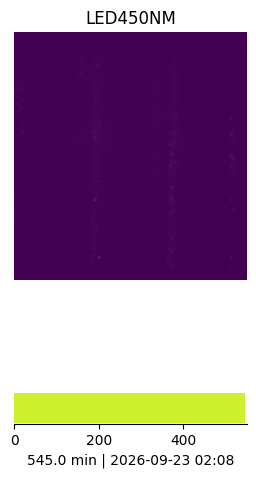

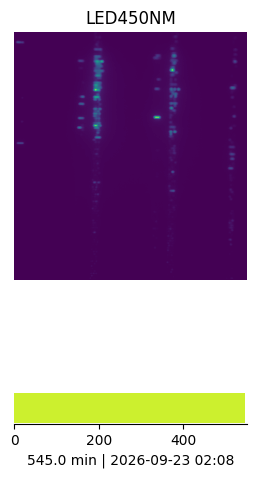

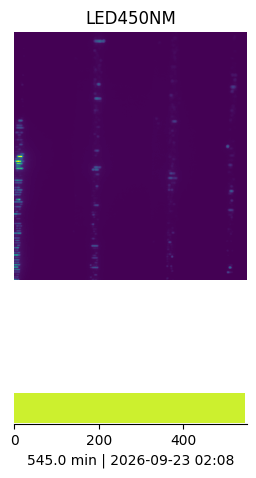

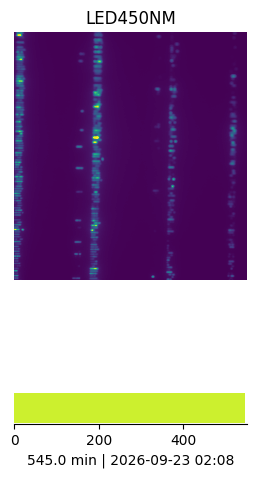

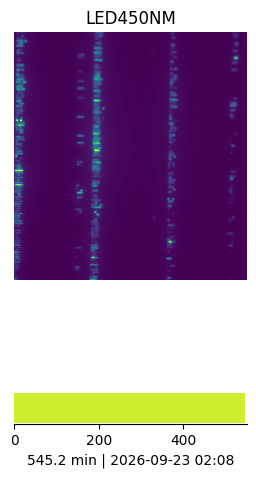

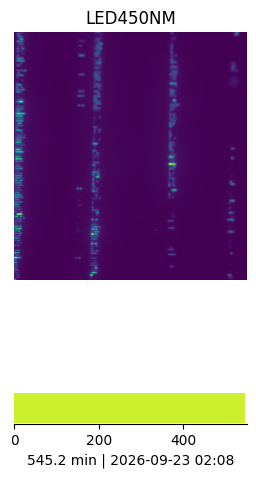

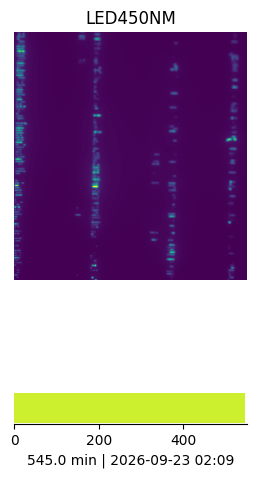

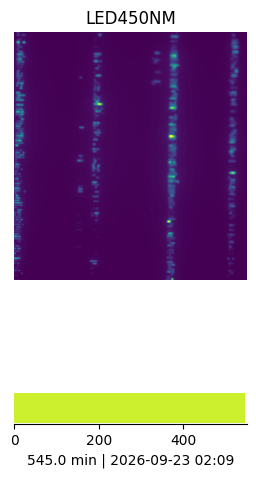

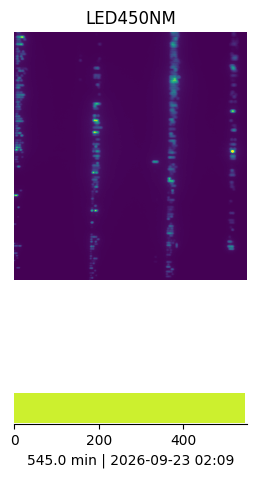

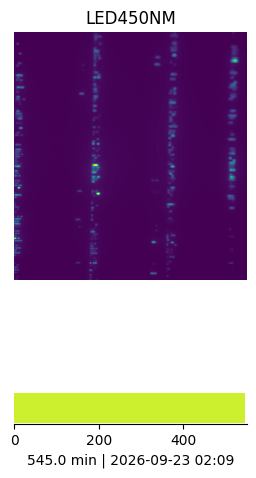

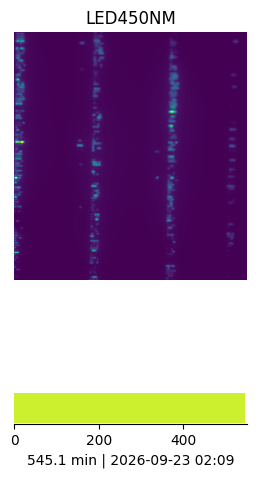

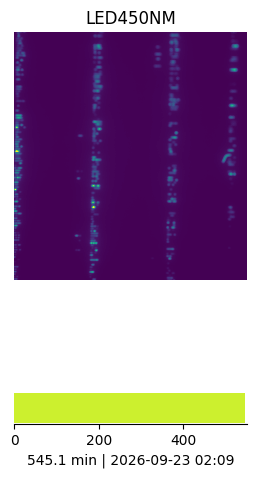

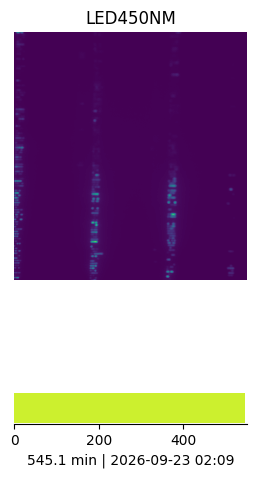

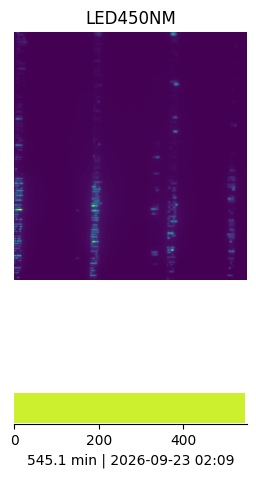

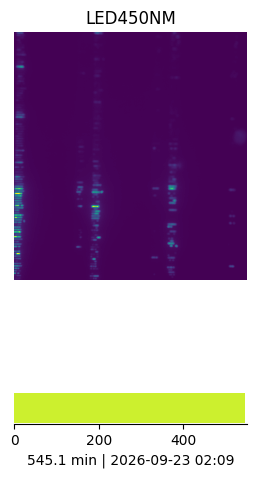

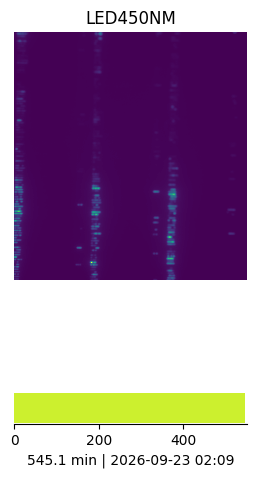

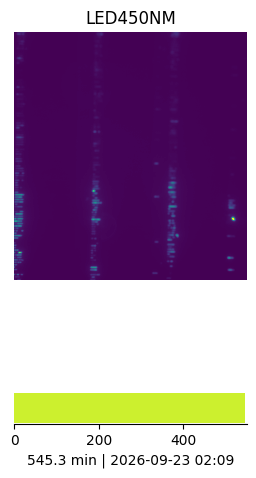

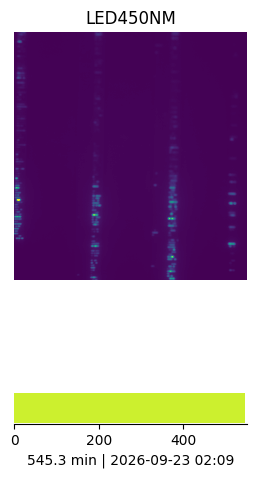

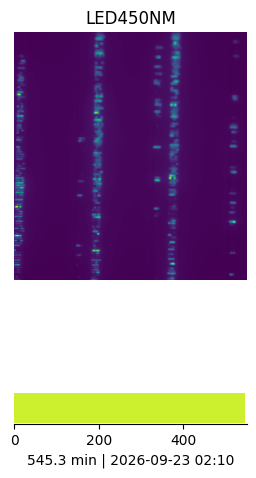

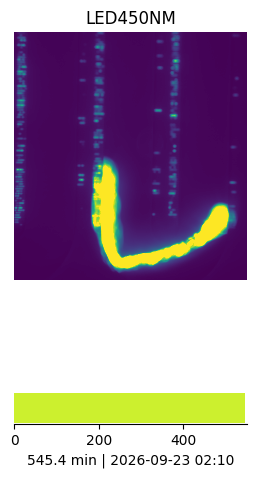

In [20]:
# Apply cropping

roi = [y_min, y_max, x_min, x_max]

# INPUT gif parameters (multiple can be selected e.g., [3, 4, 5] for FOVs 3, 4, and 5)

#fovs = [0, 1, 2,3,4,5,6,7,8]
fovs = np.unique(np.concatenate([fovs_by_led[led] for led in sel_led]))

fps = 4

timelim = 550 # minutes

# Generate GIFs for each FOV

timestamp_pattern = re.compile(r"(\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2}-\d{6})")
timestamp_format = "%Y-%m-%d_%H-%M-%S-%f"

fov_index_by_led = {
    led: {fov: i for i, fov in enumerate(fovs_by_led[led])}
    for led in sel_led
}

for p in fovs:
    frame_images_by_led = {}
    times_by_led = {}

    for led in sel_led:
        frame_files = filenames_by_fov_by_led[led][p]
        fov_index = fov_index_by_led[led][p]
        frame_images_by_led[led] = [
            image[roi[0]:roi[1], roi[2]:roi[3]] for image in imgs_by_led[led][fov_index]
        ]

        timestamps = [timestamp_pattern.search(Path(f).name).group(1) for f in frame_files]
        times_by_led[led] = [datetime.datetime.strptime(ts, timestamp_format) for ts in timestamps]

    n_frames_by_led = {led: len(frame_images_by_led[led]) for led in sel_led}
    print(f"FOV {p} frame counts: {n_frames_by_led}")

    n_frames = max(n_frames_by_led.values()) if n_frames_by_led else 0

    time_led = max(n_frames_by_led, key=n_frames_by_led.get)
    t0 = times_by_led[time_led][0]
    minutes = [(t - t0).total_seconds() / 60.0 for t in times_by_led[time_led]]
    total_minutes = minutes[-1] if minutes else 0.0

    if minutes and minutes[-1] > timelim:
        cutoff_idx = next((i for i, m in enumerate(minutes) if m > timelim), len(minutes))
        if cutoff_idx == 0:
            print(f"FOV {p} exceeds timelim before first frame; skipping.")
            continue
        n_frames = min(n_frames, cutoff_idx)
        total_minutes = timelim

    fig = plt.figure(figsize=(3 * len(sel_led), 6))
    gs = fig.add_gridspec(2, len(sel_led), height_ratios=[12, 1])
    ax_imgs = [fig.add_subplot(gs[0, i]) for i in range(len(sel_led))]
    ax_bar = fig.add_subplot(gs[1, :])

    def update(frame):
        for ax in ax_imgs:
            ax.clear()
        ax_bar.clear()

        for i, led in enumerate(sel_led):
            frame_idx = min(frame, len(frame_images_by_led[led]) - 1)
            frame_img = frame_images_by_led[led][frame_idx]

            if AUTO_BRIGHTNESS:
                v_min = np.percentile(frame_img, v_min_perc[i])
                v_max = np.percentile(frame_img, v_max_perc[i])
            else:
                v_min, v_max = FIXED_RANGES[led]
            ax_imgs[i].imshow(frame_img, cmap="viridis", vmin=v_min, vmax=v_max)
            ax_imgs[i].axis("off")
            ax_imgs[i].set_title(led)

        time_idx = min(frame, len(minutes) - 1)
        # Time bar with relative + absolute time (from LED with most frames)
        ax_bar.barh([0], [minutes[time_idx]], height=0.6, color="#ccf02e")
        ax_bar.set_xlim(0, max(total_minutes, 1e-6))
        ax_bar.set_yticks([])
        abs_time = times_by_led[time_led][time_idx].strftime("%Y-%m-%d %H:%M")
        ax_bar.set_xlabel(f"{minutes[time_idx]:.1f} min | {abs_time}")
        ax_bar.spines["top"].set_visible(False)
        ax_bar.spines["right"].set_visible(False)
        ax_bar.spines["left"].set_visible(False)

    animation = FuncAnimation(fig, update, frames=range(0, n_frames), interval=200)

    print(f"Generating FOV{p} gif...")
    if AUTO_BRIGHTNESS:
        gif_path = output_path / f"{data_folder}___{sel_led}___FOV_no{p}___AUTO_BRIGHTNESS.gif"
    else:
        gif_path = output_path / f"{data_folder}___{sel_led}___FOV_no{p}___FIXED_BRIGHTNESS.gif"
    animation.save(gif_path, fps=fps)
    print(f"FOV{p} gif generated and saved!")

In [8]:
# ================================================================
# SAVE FULL-RESOLUTION VIRIDIS PNG FRAMES
# ONE AUTOMATIC BRIGHTNESS RANGE PER FOV
#
# For each FOV:
#   1. Uses EVERY frame to calculate the brightness distribution
#   2. Samples every 10th pixel in X/Y to reduce RAM usage
#   3. Calculates ONE vmin/vmax from the pooled sampled pixels
#   4. Applies that SAME vmin/vmax to every frame in the FOV
#   5. Saves full-resolution viridis PNGs
#
# Result:
#   Brightness is directly comparable between frames WITHIN an FOV.
#   Brightness is NOT directly comparable between different FOVs,
#   because each FOV gets its own vmin/vmax.
# ================================================================

from pathlib import Path
import numpy as np
import matplotlib
from matplotlib.colors import Normalize
from skimage import io


# ------------------------------------------------
# SETTINGS
# ------------------------------------------------

LOW_PERCENTILE = 20
HIGH_PERCENTILE = 99.8

PIXEL_SAMPLE_STEP = 10

# Select FOVs to process
FOVS_TO_PROCESS = [4]

png_output_path = output_path / "PNG_frames_FOV_brightness"
png_output_path.mkdir(parents=True, exist_ok=True)

cmap = matplotlib.colormaps["viridis"]


# ------------------------------------------------
# PROCESS EACH LED
# ------------------------------------------------

for led in sel_led:

    print("\n" + "=" * 60)
    print(f"Processing {led}")
    print("=" * 60)

    for fov_index, image_collection in enumerate(imgs_by_led[led]):

        # Actual FOV number
        fov = fovs_by_led[led][fov_index]

        # Only process selected FOVs
        if fov not in FOVS_TO_PROCESS:
            continue

        print(f"\nFOV {fov}")
        print(
            f"  Calculating brightness range from "
            f"{len(image_collection)} frames..."
        )

        # ========================================================
        # STEP 1
        # Calculate ONE brightness range using ALL frames
        # ========================================================

        sampled_pixels = []

        for img in image_collection:

            # Apply the same crop used for the PNG/GIF
            cropped = img[
                y_min:y_max,
                x_min:x_max
            ]

            # Sample pixels to reduce memory usage.
            # This does NOT affect the resolution of saved PNGs.
            sampled = cropped[
                ::PIXEL_SAMPLE_STEP,
                ::PIXEL_SAMPLE_STEP
            ]

            sampled_pixels.append(sampled.ravel())

        # Combine sampled pixels from ALL frames in this FOV
        sampled_pixels = np.concatenate(sampled_pixels)

        # Calculate one vmin/vmax for the entire FOV
        v_min = np.percentile(
            sampled_pixels,
            LOW_PERCENTILE
        )

        v_max = np.percentile(
            sampled_pixels,
            HIGH_PERCENTILE
        )

        print(
            f"  {LOW_PERCENTILE}th percentile: "
            f"{v_min:.1f}"
        )

        print(
            f"  {HIGH_PERCENTILE}th percentile: "
            f"{v_max:.1f}"
        )

        print(
            f"  Fixed FOV range: "
            f"{v_min:.1f} - {v_max:.1f}"
        )

        # Free the large temporary array
        del sampled_pixels

        # ========================================================
        # STEP 2
        # Create ONE normalization for this entire FOV
        # ========================================================

        norm = Normalize(
            vmin=v_min,
            vmax=v_max,
            clip=True
        )

        # ========================================================
        # STEP 3
        # Create output folder for this FOV
        # ========================================================

        fov_output_path = (
            png_output_path
            / f"FOV_no{fov}_comparable_brightness_within_FOV"
        )

        fov_output_path.mkdir(
            parents=True,
            exist_ok=True
        )

        print(
            f"  Saving {len(image_collection)} "
            f"full-resolution PNGs..."
        )

        # ========================================================
        # STEP 4
        # Apply SAME brightness range to EVERY frame
        # ========================================================

        for frame_index, img in enumerate(image_collection):

            # Full-resolution crop
            cropped = img[
                y_min:y_max,
                x_min:x_max
            ]

            # Apply the SAME normalization to every frame
            normalized = norm(cropped)

            # Apply viridis colormap
            rgba = cmap(normalized)

            # Remove alpha channel and convert to 8-bit RGB
            rgb = (
                rgba[:, :, :3] * 255
            ).astype(np.uint8)

            # ------------------------------------------------
            # Output filename
            # ------------------------------------------------

            png_path = (
                fov_output_path
                / (
                    f"{led}_FOV{fov}_"
                    f"frame_{frame_index:04d}.png"
                )
            )

            # ------------------------------------------------
            # Save full-resolution PNG
            # ------------------------------------------------

            io.imsave(
                png_path,
                rgb,
                check_contrast=False
            )

        print(
            f"  FOV {fov} complete: "
            f"{len(image_collection)} frames saved."
        )

        print(
            f"  All frames used range "
            f"{v_min:.1f} - {v_max:.1f}"
        )


# ------------------------------------------------
# FINISHED
# ------------------------------------------------

print("\n" + "=" * 60)
print("ALL PNG IMAGES GENERATED")
print("=" * 60)

print(f"Output directory:")
print(png_output_path)


Processing LED450NM

FOV 4
  Calculating brightness range from 136 frames...
  20th percentile: 241.0
  99.8th percentile: 9710.0
  Fixed FOV range: 241.0 - 9710.0
  Saving 136 full-resolution PNGs...
  FOV 4 complete: 136 frames saved.
  All frames used range 241.0 - 9710.0

ALL PNG IMAGES GENERATED
Output directory:
/mnt/large_storage/shared_storage/data/Yuhang/2026-09-15_wmmet+ test1/GIFs/PNG_frames_FOV_brightness
